# Chapter 2 problem set — From one perceptron to networks

| | |
| --- | --- |
| **Prerequisites** | Notebooks 07–12 |
| **Covers** | Hand-constructed step networks, second-order optimization of logistic regression, a silent data bug in multiclass training, constructed versus trained ReLU networks |
| **Estimated time** | 4–5 hours |
| **Compute** | CPU |

These problems combine ideas from the whole chapter. Each has automated checks; problems 2 and 4 also ask for a short written analysis. Attempt each problem before opening its hint.

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math

import torch.nn as nn
import torch.nn.functional as F

from dlcourse.data import make_blobs, make_checkerboard
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

## Problem 1: A 16-tile checkerboard from step units

*Notebooks 08 and 11.* `make_checkerboard(tiles=4)` colors the square $[-1, 1]^2$ like a 4×4 checkerboard. Each tile is $0.5 \times 0.5$, and a point's class is the parity of its tile's column index plus its row index:

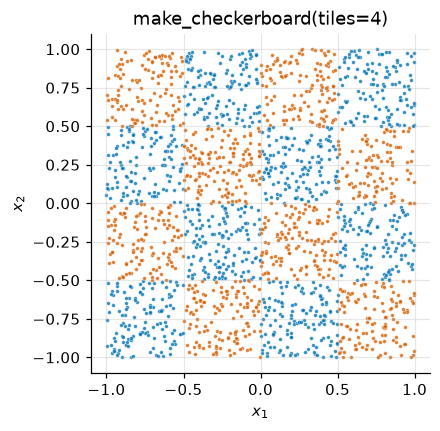

In [3]:
X_board, y_board = make_checkerboard(n=2000, tiles=4, seed=0)
plot_dataset(X_board, y_board, title="make_checkerboard(tiles=4)", s=6)
plt.show()

**Your task:** build a network of **step units**, $\operatorname{step}(z) = 1$ if $z > 0$ else $0$, that classifies every point correctly. Use exactly this architecture, so that no training is needed — only reasoning:

| Layer | Units | Role |
| --- | --- | --- |
| 1 | 6 | One unit per grid line: $x_1 = -0.5, 0, 0.5$ and $x_2 = -0.5, 0, 0.5$ |
| 2 | 2 | An OR unit and a NAND unit |
| 3 | 1 | An AND unit: the class |

Store the layers as `board_layers = [(W1, b1), (W2, b2), (W3, b3)]` with `nn.Linear`'s layout: `W1` is `(6, 2)`, `W2` is `(2, 6)`, `W3` is `(1, 2)`. The function below runs them.

Plan it in two steps:

1. **Column parity.** Let $s_1, s_2, s_3$ be the outputs of the units for $x_1 > -0.5$, $x_1 > 0$, $x_1 > 0.5$. The column index is $i = s_1 + s_2 + s_3$. Because the thresholds are ordered, $s_1 \ge s_2 \ge s_3$. Show that the column parity $i \bmod 2$ equals the **linear** expression $s_1 - s_2 + s_3$. The same holds for rows.
2. **XOR of parities.** The class is $(i + j) \bmod 2 = \operatorname{XOR}(i \bmod 2,\ j \bmod 2)$. Notebook 11 built XOR as AND(OR, NAND). Each of the OR and NAND units reads the two parities — and each parity is a linear combination of layer-1 outputs, so it can be folded into the layer-2 weights.

In [4]:
def step(z):
    return (z > 0).float()


def run_step_network(X, layers):
    """Apply step(X @ W.T + b) for each (W, b) in layers; return labels of shape (N,)."""
    h = X
    for W, b in layers:
        h = step(h @ W.T + b)
    return h.squeeze(1).long()

<details>
<summary><b>💡 Hint</b></summary>

Layer 1: rows `[1, 0]` with biases `0.5, 0, -0.5` (for $x_1 > -0.5$, $x_1 > 0$, $x_1 > 0.5$), then the same with `[0, 1]`. Layer 2: OR of the parities is `step(cx + cy - 0.5)`, so its weights are `[1, -1, 1, 1, -1, 1]` with bias `-0.5`. NAND is `step(-(cx + cy) + 1.5)`. Layer 3: AND is `step(h1 + h2 - 1.5)`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(len(board_layers) == 3, f"board_layers should have 3 layers, got {len(board_layers)}")
for (W, b), shape in zip(board_layers, [(6, 2), (2, 6), (1, 2)]):
    check_shape(W, shape, "layer weight")
    check_shape(b, (shape[0],), "layer bias")
predictions = run_step_network(X_board, board_layers)
accuracy = (predictions == y_board).float().mean().item()
check(accuracy == 1.0, f"accuracy is {accuracy:.3f}; every point should be classified correctly")
passed("Problem 1")

In [7]:
if "board_layers" in globals():
    plot_decision_boundary(lambda P: run_step_network(P, board_layers), X_board, y_board, title="Your step network's decision regions")
    plt.show()

## Problem 2: Newton's method for logistic regression

*Notebooks 03, 06, and 09.* Gradient descent uses only the slope. **Newton's method** also uses the curvature: it fits a quadratic to the loss at the current point and jumps to that quadratic's minimum,

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - H^{-1}\, \nabla L(\boldsymbol\theta),$$

where $H$ is the Hessian. For logistic regression with augmented inputs $\tilde{X}$ (a column of ones appended, so $\boldsymbol\theta = (\mathbf{w}, b)$), notebook 09 derived

$$\nabla L = \tfrac{1}{N}\tilde{X}^\top(\hat{\mathbf p} - \mathbf y), \qquad H = \tfrac{1}{N}\tilde{X}^\top \operatorname{diag}\big(\hat{\mathbf p} \odot (1 - \hat{\mathbf p})\big)\, \tilde{X}.$$

### 2a. Implement it

Write `newton_logistic(X_aug, y, steps)` returning `(theta, losses)`: the final parameters, shape `(D + 1,)`, and the list of binary cross-entropy losses **before** each step. Start from $\boldsymbol\theta = \mathbf 0$. Use `torch.linalg.solve(H, g)` rather than forming $H^{-1}$ explicitly; it is faster and more accurate. Work in `float64`.

In [8]:
X_lr, y_lr = make_blobs(n=200, centers=((-0.6, -0.4), (0.6, 0.5)), std=0.7, seed=3)
X_aug = torch.cat([X_lr, torch.ones(len(X_lr), 1)], dim=1).double()  # (400, 3)
y_lr = y_lr.double()

<details>
<summary><b>💡 Hint</b></summary>

In each step: `p = torch.sigmoid(X_aug @ theta)`, record the loss with `F.binary_cross_entropy(p, y)`, form `g = X_aug.T @ (p - y) / N` and `H = (X_aug * (p * (1 - p)).unsqueeze(1)).T @ X_aug / N`, then `theta = theta - torch.linalg.solve(H, g)`. Multiplying the rows of `X_aug` by the weights is the same as the `diag(...)` product, without building an `N × N` matrix.

</details>

In [ ]:
def newton_logistic(X_aug, y, steps=10):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
theta_newton, newton_losses = newton_logistic(X_aug, y_lr, steps=10)
check_shape(theta_newton, (3,), "theta from newton_logistic")
check(len(newton_losses) == 10, f"expected 10 recorded losses, got {len(newton_losses)}")
p_final = torch.sigmoid(X_aug @ theta_newton)
gradient = X_aug.T @ (p_final - y_lr) / len(y_lr)
check(gradient.abs().max().item() < 1e-10, f"gradient at the result is {gradient.abs().max().item():.2e}; Newton's method should reach ~0 in 10 steps")
reference = nn.Linear(2, 1).double()
optimizer = torch.optim.LBFGS(reference.parameters(), max_iter=200, tolerance_grad=1e-12, tolerance_change=1e-14)
def closure():
    optimizer.zero_grad()
    loss = F.binary_cross_entropy_with_logits(reference(X_aug[:, :2]).squeeze(1), y_lr)
    loss.backward()
    return loss
optimizer.step(closure)
check_close(theta_newton, torch.cat([reference.weight.detach().squeeze(0), reference.bias.detach()]), "theta vs an L-BFGS reference", atol=1e-6)
passed("Problem 2a")

### 2b. Investigate: how fast is Newton's method?

The cell below runs gradient descent with the largest safe fixed learning rate, $\eta = 1/\lambda_{\max}$ of the Hessian at $\boldsymbol\theta = \mathbf 0$ (where it is largest, since $\hat p(1-\hat p) \le 1/4$), and plots both methods' **loss gap** — loss minus the optimal loss — against the iteration number. Run it, then answer in the markdown cell below:

1. Describe each curve's shape on the log scale. How many steps does each need to reach a gap of $10^{-12}$?
2. Count the arithmetic per step for $D$ parameters and $N$ examples: forming $H$, and solving with it. Why is Newton's method not used to train networks with millions of parameters?
3. What would happen to Newton's method on **perfectly separable** data (notebook 09, section 7)?

In [ ]:
best_loss = min(newton_losses)
theta_gd = torch.zeros(3, dtype=torch.float64)
H0 = X_aug.T @ X_aug * 0.25 / len(y_lr)
lr_gd = 1.0 / torch.linalg.eigvalsh(H0).max().item()
gd_gaps = []
for _ in range(400):
    p = torch.sigmoid(X_aug @ theta_gd)
    gd_gaps.append(F.binary_cross_entropy(p, y_lr).item() - best_loss)
    theta_gd -= lr_gd * X_aug.T @ (p - y_lr) / len(y_lr)

_, long_newton = newton_logistic(X_aug, y_lr, steps=8)
newton_gaps = [loss - best_loss for loss in long_newton]
plt.semilogy([max(g, 1e-17) for g in gd_gaps], label=f"gradient descent (η = {lr_gd:.2f})")
plt.semilogy([max(g, 1e-17) for g in newton_gaps], "o-", label="Newton's method")
plt.axhline(1e-12, color="gray", ls=":", lw=1)
plt.xlabel("iteration")
plt.ylabel("loss − optimal loss (floored at 1e-17)")
plt.title("Logistic regression: first- vs second-order optimization")
plt.legend()
plt.show()
for name, gaps in [("gradient descent", gd_gaps), ("Newton", newton_gaps)]:
    reached = next((i for i, g in enumerate(gaps) if g < 1e-12), None)
    print(f"{name:17s}: first iteration with gap < 1e-12: {reached}")

*Your answers:*

## Problem 3: The classifier that learns nothing

*Notebooks 06 and 10.* `prepare` shuffles a dataset before training, a common habit. After the "improvement", this softmax regression trains without errors but its accuracy sits near chance. Find and fix the bug in `prepare`.

In [12]:
X_three, y_three = make_blobs(n=150, centers=((-1.5, 0.0), (1.5, 0.0), (0.0, 2.0)), std=0.5, seed=4)


def train_softmax(X, y, steps=300, lr=0.5):
    torch.manual_seed(0)
    model = nn.Linear(2, 3)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.cross_entropy(model(X), y)
        loss.backward()
        optimizer.step()
    accuracy = (model(X).argmax(dim=1) == y).float().mean().item()
    return loss.item(), accuracy

<details>
<summary><b>💡 Hint</b></summary>

Each row of `X` belongs with the label in the same row of `y`. How many random permutations does the buggy code draw?

</details>

In [ ]:
def prepare(X, y, seed=0):
    gen = torch.Generator().manual_seed(seed)
    # Buggy version:
    #     X = X[torch.randperm(len(X), generator=gen)]
    #     y = y[torch.randperm(len(y), generator=gen)]
    #     return X, y
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
X_shuf, y_shuf = prepare(X_three, y_three)
check(torch.equal(torch.sort(y_shuf).values, torch.sort(y_three).values), "prepare must keep the same labels, only reordered")
final_loss, accuracy = train_softmax(X_shuf, y_shuf)
print(f"final loss {final_loss:.3f} (ln 3 = {math.log(3):.3f}), training accuracy {accuracy:.3f}")
check(accuracy > 0.95, f"training accuracy is {accuracy:.3f}; the labels no longer match their inputs")
passed("Problem 3")

## Problem 4: Constructed versus trained ReLU networks

*Notebook 12.* Notebook 12 *constructed* one-hidden-layer ReLU networks that interpolate a function, with error falling like $1/H^2$ in the number of units $H$. Does gradient descent find networks that good?

### 4a. A training function

Write `train_relu_net(H, x, y, steps, seed)` that creates `nn.Sequential(nn.Linear(1, H), nn.ReLU(), nn.Linear(H, 1))` after `torch.manual_seed(seed)`, trains it on inputs `x` and targets `y` (both shape `(N, 1)`) with full-batch `torch.optim.Adam(lr=0.01)` and the MSE loss for `steps` steps, and returns the trained model.

<details>
<summary><b>💡 Hint</b></summary>

The same 5-line training step as notebook 06, with `torch.optim.Adam(model.parameters(), lr=0.01)` in place of SGD. Adam (notebook 19) adapts each parameter's step size, which makes it far less sensitive to the learning rate here.

</details>

In [ ]:
def train_relu_net(H, x, y, steps=3000, seed=0):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
x_check = torch.linspace(-1, 1, 50).unsqueeze(1)
model_check = train_relu_net(8, x_check, x_check.abs(), steps=1500, seed=0)
check(isinstance(model_check, nn.Sequential), "train_relu_net should return the nn.Sequential model")
check_shape(model_check(x_check), (50, 1), "model output")
check(F.mse_loss(model_check(x_check), x_check.abs()).item() < 1e-3, "the network should fit |x| with 8 units almost exactly")
passed("Problem 4a")

### 4b. Investigate

The cell below fits $\sin(x)$ on $[-\pi, \pi]$ from 200 noise-free samples, for several widths $H$ and 3 seeds each, and measures the maximum error on a dense grid. It compares the best trained network with the **constructed** interpolant of notebook 12, which uses $H$ units for $H + 1$ equally spaced knots. Run it (about 30 seconds), then answer:

1. How does the error of the trained networks change with $H$, compared with the construction's $1/H^2$ rate?
2. How much do the three seeds differ? What does that say about "the network with $H$ units" as a single object?
3. Notebook 12 showed that a network of a given size *can represent* a good approximation. What does this experiment add?

In [ ]:
x_train = torch.linspace(-math.pi, math.pi, 200).unsqueeze(1)
y_train = torch.sin(x_train)
x_dense = torch.linspace(-math.pi, math.pi, 5001).unsqueeze(1)
y_dense = torch.sin(x_dense)


def interpolation_error(H):
    knots = torch.linspace(-math.pi, math.pi, H + 1, dtype=torch.float64)
    xd = x_dense.squeeze(1).double()
    idx = torch.searchsorted(knots, xd).clamp(1, H)
    x0, x1 = knots[idx - 1], knots[idx]
    t = (xd - x0) / (x1 - x0)
    interp = (1 - t) * torch.sin(x0) + t * torch.sin(x1)
    return (interp - torch.sin(xd)).abs().max().item()


widths = [2, 4, 8, 16, 32]
trained = {}
for H in widths:
    errors = []
    for seed in range(3):
        model = train_relu_net(H, x_train, y_train, steps=3000, seed=seed)
        with torch.no_grad():
            errors.append((model(x_dense) - y_dense).abs().max().item())
    trained[H] = errors
    print(f"H = {H:>2}: trained max errors {[f'{e:.4f}' for e in errors]}   constructed {interpolation_error(H):.4f}")

plt.loglog(widths, [min(trained[H]) for H in widths], "o-", label="trained: best of 3 seeds")
plt.loglog(widths, [max(trained[H]) for H in widths], "o:", color=COLORS[0], alpha=0.6, label="trained: worst of 3 seeds")
plt.loglog(widths, [interpolation_error(H) for H in widths], "s-", label="constructed interpolant")
plt.xlabel("hidden units H")
plt.ylabel("max |network − sin| on [−π, π]")
plt.title("Approximating sin: constructed vs trained one-hidden-layer ReLU networks")
plt.legend()
plt.show()

*Your answers:*